# Dataset 2 for analysis/demonstration

## Part 1: Test set (10%) MSE Comparsion for 30% (aug), 60%(non-aug/ "true"), 90% (all training) 

In [1]:
import json

# Open the file and load its contents
with open("C:/Users/bandarua/crda_gp/data/matbench_expt_gap.json", 'r') as file:
    data = json.load(file)

data.keys()

dict_keys(['index', 'columns', 'data'])

In [2]:
import numpy as np 
data_array = np.array(data['data'])

In [3]:
# Composition and yield dictionary
my_data = {}
for i in range(len(data['columns'])):
    my_data[data['columns'][i]] = []
    for j in range(len(data['data'])):
        my_data[data['columns'][i]].append(data['data'][j][i])

In [4]:
from collections import defaultdict

def parse_formula(compound: str):
    stack = [defaultdict(int)]
    i = 0

    while i < len(compound):
        char = compound[i]

        if char == '(':
            stack.append(defaultdict(int))
            i += 1

        elif char == ')':
            i += 1

            num = ""
            while i < len(compound) and compound[i].isdigit():
                num += compound[i]
                i += 1
            multiplier = int(num) if num else 1

            # Pop current group and merge into previous
            group = stack.pop()
            for element, count in group.items():
                stack[-1][element] += count * multiplier

        elif char.isupper():
            element = char
            i += 1
            while i < len(compound) and compound[i].islower():
                element += compound[i]
                i += 1

            # Read atom count
            num = ""
            while i < len(compound) and compound[i].isdigit():
                num += compound[i]
                i += 1
            count = int(num) if num else 1

            stack[-1][element] += count
        
        else:
            i += 1
    
    return dict(stack[0])

In [5]:
my_data['split_composition'] = []
for composition in my_data['composition']:
    my_data['split_composition'].append(parse_formula(composition))
# my_data['split_composition']

In [6]:
key_count = []
for keys in my_data['split_composition']:
    for key in keys:
        key_count.append(key)
key_count = list(set(key_count))
# key_count

In [7]:
composition_dict = {}

for key in key_count:
    composition_dict[key] = []
    for comp in my_data['split_composition']:
        if key in list(comp.keys()):
            composition_dict[key].append(comp[key])
        else:
            composition_dict[key].append(0)

In [8]:
import pandas as pd
df = pd.DataFrame(data=composition_dict)
# df

In [9]:
df_targets = pd.DataFrame(my_data['gap expt'], columns=["gap_expt"])
# df_targets

In [10]:
df_final = pd.concat([df, df_targets], axis=1)
df_final

,Bi,Mn,Sm,Ni,F,Ag,Br,V,Cu,Sc,...,La,Th,N,H,Ta,Ti,Rh,Sn,Zr,gap_expt
0,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0.00
1,0,0,0,0,0,1,14,0,0,0,...,0,0,0,0,0,0,0,0,0,0.00
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1.83
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1.51
4,0,0,0,0,0,2,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4599,0,0,0,0,0,0,0,0,0,0,...,0,0,3,0,1,0,0,0,1,1.72
4600,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0.00
4601,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,0,0,1,0.00
4602,0,0,0,0,6,0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,0.00


In [11]:
from crda_gp.utils import set_seed
from sklearn.model_selection import train_test_split
import torch


set_seed(42)

X = np.array(df_final.drop(columns="gap_expt"))
y = np.array(df_final["gap_expt"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

# Turn the data splits into torch.Tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

In [12]:
from crda_gp.models import ARDExactGPModel_Sparse
import gpytorch
set_seed(42)
likelihood = gpytorch.likelihoods.GaussianLikelihood()
model = ARDExactGPModel_Sparse(train_x=X_train_tensor,
                               train_y=y_train_tensor,
                               likelihood=likelihood)

In [13]:
from crda_gp.utils import train_step
set_seed(42)
train_step(X_train=X_train_tensor,
           y_train=y_train_tensor,
           model=model,
           likelihood=likelihood)

Iter: 10/100 | Loss: 1.441 | Noise: 0.343
Iter: 20/100 | Loss: 1.431 | Noise: 0.252
Iter: 30/100 | Loss: 1.423 | Noise: 0.177
Iter: 40/100 | Loss: 1.428 | Noise: 0.139
Iter: 50/100 | Loss: 1.441 | Noise: 0.143
Iter: 60/100 | Loss: 1.432 | Noise: 0.186
Iter: 70/100 | Loss: 1.427 | Noise: 0.198
Iter: 80/100 | Loss: 1.426 | Noise: 0.177
Iter: 90/100 | Loss: 1.428 | Noise: 0.165
Iter: 100/100 | Loss: 1.426 | Noise: 0.178


In [14]:
from crda_gp.utils import val_step
set_seed(42)
y_pred = val_step(X_test=X_test_tensor,
                  model=model,
                  likelihood=likelihood)

In [15]:
from sklearn.metrics import mean_squared_error
set_seed(42)
MSE = mean_squared_error(y_true=y_test_tensor, 
                         y_pred=y_pred)

In [16]:
MSE

0.9198886156082153

In [17]:
# Splitting the train data into augment and true values respectively
X_train_aug, X_train_true, y_train_aug, y_train_true = train_test_split(X_train, y_train, test_size=(0.6*len(X)/len(X_train)), random_state=42)
# Change the data into tensors
X_train_aug_tensor = torch.tensor(X_train_aug, dtype=torch.float32)
X_train_true_tensor = torch.tensor(X_train_true, dtype=torch.float32)
y_train_aug_tensor = torch.tensor(y_train_aug, dtype=torch.float32)
y_train_true_tensor = torch.tensor(y_train_true, dtype=torch.float32)

In [18]:
likelihood_true = gpytorch.likelihoods.GaussianLikelihood()
model_true = ARDExactGPModel_Sparse(train_x=X_train_true_tensor,
                                   train_y=y_train_true_tensor,
                                   likelihood=likelihood_true)

In [19]:
train_step(X_train=X_train_true_tensor, 
           y_train=y_train_true_tensor,
           model=model_true,
           likelihood=likelihood_true)

Iter: 10/100 | Loss: 1.475 | Noise: 0.349
Iter: 20/100 | Loss: 1.463 | Noise: 0.256
Iter: 30/100 | Loss: 1.463 | Noise: 0.199
Iter: 40/100 | Loss: 1.469 | Noise: 0.183
Iter: 50/100 | Loss: 1.463 | Noise: 0.211
Iter: 60/100 | Loss: 1.467 | Noise: 0.275
Iter: 70/100 | Loss: 1.455 | Noise: 0.252
Iter: 80/100 | Loss: 1.467 | Noise: 0.222
Iter: 90/100 | Loss: 1.462 | Noise: 0.211
Iter: 100/100 | Loss: 1.470 | Noise: 0.252


In [20]:
y_pred_true = val_step(X_test=X_test_tensor, 
                       model=model_true, 
                       likelihood=likelihood_true)

In [21]:
MSE_true = mean_squared_error(y_test_tensor, y_pred_true)
MSE_true

1.0500959157943726

In [22]:
MSE

0.9198886156082153

In [23]:
likelihood_aug = gpytorch.likelihoods.GaussianLikelihood()
model_aug = ARDExactGPModel_Sparse(train_x=X_train_aug_tensor, 
                                  train_y=y_train_aug_tensor, 
                                  likelihood=likelihood_aug)

In [24]:
train_step(X_train=X_train_aug_tensor, 
           y_train=y_train_aug_tensor,
           model=model_aug,
           likelihood=likelihood_aug)

Iter: 10/100 | Loss: 1.541 | Noise: 0.353
Iter: 20/100 | Loss: 1.544 | Noise: 0.231
Iter: 30/100 | Loss: 1.535 | Noise: 0.197
Iter: 40/100 | Loss: 1.540 | Noise: 0.225
Iter: 50/100 | Loss: 1.525 | Noise: 0.268
Iter: 60/100 | Loss: 1.536 | Noise: 0.260
Iter: 70/100 | Loss: 1.525 | Noise: 0.236
Iter: 80/100 | Loss: 1.543 | Noise: 0.246
Iter: 90/100 | Loss: 1.525 | Noise: 0.260
Iter: 100/100 | Loss: 1.535 | Noise: 0.241


In [25]:
y_pred_aug = val_step(X_test=X_test_tensor, 
                      model=model_aug, 
                      likelihood=likelihood_aug)

In [26]:
MSE_aug = mean_squared_error(y_test_tensor, y_pred_aug)
MSE_aug

1.1230950355529785

In [27]:
MSE

0.9198886156082153

In [28]:
with torch.no_grad(), gpytorch.settings.fast_pred_var():
    pred_dist = likelihood_aug(model_aug(X_train_aug_tensor))
    y_new_aug = pred_dist.mean

residual = y_train_aug_tensor - y_new_aug
corr = abs(pd.DataFrame(X_train).corrwith(pd.Series(residual)))

preturb_idx= corr[abs(corr) < corr.mean().item()].sort_values(ascending=False).index.values
preturb_idx

c:\Users\bandarua\crda_gp\env\Lib\site-packages\gpytorch\models\exact_gp.py:299: GPInputWarning: The input matches the stored training data. Did you forget to call model.train()?
  warnings.warn(
c:\Users\bandarua\crda_gp\env\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\bandarua\crda_gp\env\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


array([49, 35, 52, 54,  6, 22, 55,  4, 62,  9,  5, 41, 13, 68, 38, 77, 70,
       72, 19, 10, 74, 18, 44, 20, 46, 76, 12, 71, 15, 48, 63, 30, 31, 11,
       65,  8, 80, 37, 29, 50,  2, 17, 21, 26, 39, 27, 32, 73, 47])

In [29]:
from crda_gp.crda import CRDA_function
X_train_aug_CRDA_tensor, y_train_aug_CRDA_tensor, _, _ = CRDA_function(X_train_aug_tensor, 
                                                                 y_train_aug_tensor, 
                                                                 model=model_aug, 
                                                                 likelihood=likelihood_aug, 
                                                                 perturb_idx=preturb_idx, 
                                                                 p=0.1)

c:\Users\bandarua\crda_gp\env\Lib\site-packages\gpytorch\models\exact_gp.py:299: GPInputWarning: The input matches the stored training data. Did you forget to call model.train()?
  warnings.warn(


Starting the Loop
Iter: 0
Iter: 1
Iter: 2
Iter: 3
Iter: 4
Iter: 5
Iter: 6
Iter: 7
Iter: 8
Iter: 9
Iter: 10
Iter: 11
Iter: 12
Iter: 13
Iter: 14
Iter: 15
Iter: 16
Iter: 17
Iter: 18
Iter: 19
Iter: 20
Iter: 21
Iter: 22
Iter: 23
Iter: 24
Iter: 25
Iter: 26
Iter: 27
Iter: 28
Iter: 29
Iter: 30
Iter: 31
Iter: 32
Iter: 33
Iter: 34
Iter: 35
Iter: 36
Iter: 37
Iter: 38
Iter: 39
Iter: 40
Iter: 41
Iter: 42
Iter: 43
Iter: 44
Iter: 45
Iter: 46
Iter: 47
Iter: 48
Iter: 49
Iter: 50
Iter: 51
Iter: 52
Iter: 53
Iter: 54
Iter: 55
Iter: 56
Iter: 57
Iter: 58
Iter: 59
Iter: 60
Iter: 61
Iter: 62
Iter: 63
Iter: 64
Iter: 65
Iter: 66
Iter: 67
Iter: 68
Iter: 69
Iter: 70
Iter: 71
Iter: 72
Iter: 73
Iter: 74
Iter: 75
Iter: 76
Iter: 77
Iter: 78
Iter: 79
Iter: 80
Iter: 81
Iter: 82
Iter: 83
Iter: 84
Iter: 85
Iter: 86
Iter: 87
Iter: 88
Iter: 89
Iter: 90
Iter: 91
Iter: 92
Iter: 93
Iter: 94
Iter: 95
Iter: 96
Iter: 97
Iter: 98
Iter: 99
Iter: 100
Iter: 101
Iter: 102
Iter: 103
Iter: 104
Iter: 105
Iter: 106
Iter: 107
Iter: 108
It

In [30]:
corr

0     0.026260
1     0.037113
2     0.002161
3     0.038526
4     0.013149
        ...   
76    0.006435
77    0.010588
78    0.025820
79    0.017687
80    0.003765
Length: 81, dtype: float64

In [31]:
likelihood_aug_new = gpytorch.likelihoods.GaussianLikelihood()
model_aug_new = ARDExactGPModel_Sparse(train_x=X_train_aug_CRDA_tensor, 
                                      train_y=y_train_aug_CRDA_tensor, 
                                      likelihood=likelihood_aug_new)

In [32]:
train_step(X_train=X_train_aug_CRDA_tensor, 
           y_train=y_train_aug_CRDA_tensor,
           model=model_aug_new,
           likelihood=likelihood_aug_new)

Iter: 10/100 | Loss: 1.152 | Noise: 0.313
Iter: 20/100 | Loss: 0.990 | Noise: 0.128
Iter: 30/100 | Loss: 0.887 | Noise: 0.053
Iter: 40/100 | Loss: 0.918 | Noise: 0.029
Iter: 50/100 | Loss: 0.866 | Noise: 0.029
Iter: 60/100 | Loss: 0.879 | Noise: 0.035
Iter: 70/100 | Loss: 0.884 | Noise: 0.037
Iter: 80/100 | Loss: 0.873 | Noise: 0.036
Iter: 90/100 | Loss: 0.907 | Noise: 0.035
Iter: 100/100 | Loss: 0.887 | Noise: 0.036


In [33]:
y_pred_aug_new = val_step(X_test=X_test_tensor, 
                      model=model_aug_new, 
                      likelihood=likelihood_aug_new)

In [34]:
MSE_aug_new = mean_squared_error(y_test_tensor, y_pred_aug_new)
MSE_aug_new

1.089358925819397

In [35]:
MSE_aug

1.1230950355529785

In [36]:
MSE_true

1.0500959157943726

In [37]:
MSE

0.9198886156082153

In [38]:
MSE_true_percentage = ((MSE_true - MSE)/MSE)*100
MSE_true_percentage

14.154681118655468

In [39]:
MSE_aug_percentage = ((MSE_aug - MSE)/MSE)*100
MSE_aug_percentage

22.09032881773479

In [40]:
MSE_aug_new_percentage = ((MSE_aug_new - MSE)/MSE)*100
MSE_aug_new_percentage

18.42291635483831

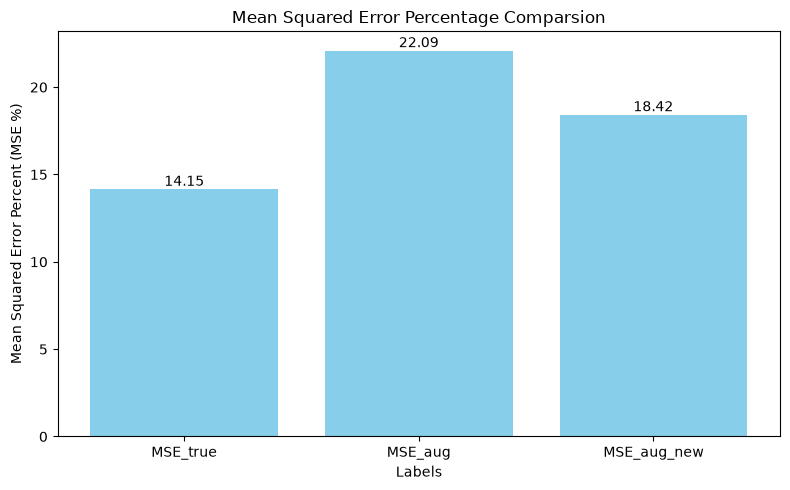

In [41]:
import matplotlib.pyplot as plt

# Example data
MSE_results_labels = ['MSE_true', 'MSE_aug', 'MSE_aug_new']
MSE_results_values = [MSE_true_percentage, MSE_aug_percentage, MSE_aug_new_percentage]

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(MSE_results_labels, MSE_results_values, color='skyblue')

plt.title('Mean Squared Error Percentage Comparsion')
plt.xlabel('Labels')
plt.ylabel('Mean Squared Error Percent (MSE %)')

# Add value labels on bars
for i, values in enumerate(MSE_results_values):
    plt.text(i, values + 0.2, f'{values:.2f}', ha='center')

plt.tight_layout()
plt.show()

## Part 2: Informative metric testing 

In [42]:
import torch
# Reusing the data
X = np.array(df_final.drop(columns="gap_expt"))
y = np.array(df_final["gap_expt"])

X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32)

In [43]:
set_seed(42)
likelihood = gpytorch.likelihoods.GaussianLikelihood()
model = ARDExactGPModel_Sparse(train_x=X_tensor,
                              train_y=y_tensor,
                              likelihood=likelihood)

In [44]:
set_seed(42)
train_step(X_train=X_tensor,
           y_train=y_tensor,
           model=model,
           likelihood=likelihood)

Iter: 10/100 | Loss: 1.436 | Noise: 0.342
Iter: 20/100 | Loss: 1.419 | Noise: 0.250
Iter: 30/100 | Loss: 1.415 | Noise: 0.173
Iter: 40/100 | Loss: 1.414 | Noise: 0.132
Iter: 50/100 | Loss: 1.427 | Noise: 0.113
Iter: 60/100 | Loss: 1.418 | Noise: 0.116
Iter: 70/100 | Loss: 1.424 | Noise: 0.125
Iter: 80/100 | Loss: 1.418 | Noise: 0.131
Iter: 90/100 | Loss: 1.424 | Noise: 0.119
Iter: 100/100 | Loss: 1.420 | Noise: 0.104


In [45]:
X_CRDA_tensor, y_CRDA_tensor, _, _ = CRDA_function(X_train=X_tensor,
                                             y_train=y_tensor,
                                             model=model,
                                             likelihood=likelihood)

c:\Users\bandarua\crda_gp\env\Lib\site-packages\gpytorch\models\exact_gp.py:299: GPInputWarning: The input matches the stored training data. Did you forget to call model.train()?
  warnings.warn(


Starting the Loop
Iter: 0
Iter: 1
Iter: 2
Iter: 3
Iter: 4
Iter: 5
Iter: 6
Iter: 7
Iter: 8
Iter: 9
Iter: 10
Iter: 11
Iter: 12
Iter: 13
Iter: 14
Iter: 15
Iter: 16
Iter: 17
Iter: 18
Iter: 19
Iter: 20
Iter: 21
Iter: 22
Iter: 23
Iter: 24
Iter: 25
Iter: 26
Iter: 27
Iter: 28
Iter: 29
Iter: 30
Iter: 31
Iter: 32
Iter: 33
Iter: 34
Iter: 35
Iter: 36
Iter: 37
Iter: 38
Iter: 39
Iter: 40
Iter: 41
Iter: 42
Iter: 43
Iter: 44
Iter: 45
Iter: 46
Iter: 47
Iter: 48
Iter: 49
Iter: 50
Iter: 51
Iter: 52
Iter: 53
Iter: 54
Iter: 55
Iter: 56
Iter: 57
Iter: 58
Iter: 59
Iter: 60
Iter: 61
Iter: 62
Iter: 63
Iter: 64
Iter: 65
Iter: 66
Iter: 67
Iter: 68
Iter: 69
Iter: 70
Iter: 71
Iter: 72
Iter: 73
Iter: 74
Iter: 75
Iter: 76
Iter: 77
Iter: 78
Iter: 79
Iter: 80
Iter: 81
Iter: 82
Iter: 83
Iter: 84
Iter: 85
Iter: 86
Iter: 87
Iter: 88
Iter: 89
Iter: 90
Iter: 91
Iter: 92
Iter: 93
Iter: 94
Iter: 95
Iter: 96
Iter: 97
Iter: 98
Iter: 99
Iter: 100
Iter: 101
Iter: 102
Iter: 103
Iter: 104
Iter: 105
Iter: 106
Iter: 107
Iter: 108
It

In [46]:
from crda_gp.utils import entropy_cal
entropies_true = entropy_cal(X=X_tensor)

In [47]:
entropies_aug = entropy_cal(X=X_CRDA_tensor)

Mean of True vs Aug: 0.12493286271007502 | 0.12418663927342238


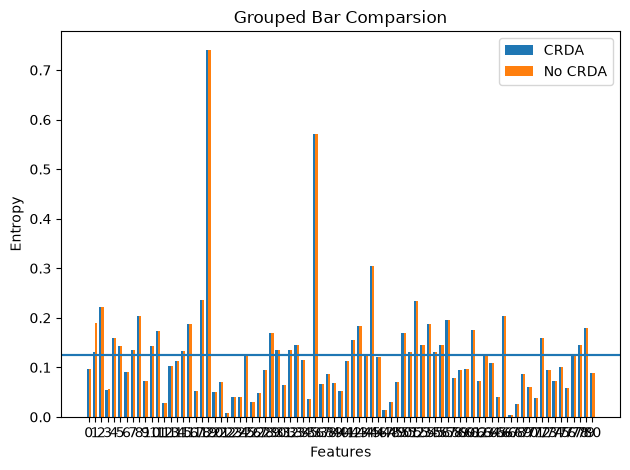

In [48]:
from crda_gp.utils import plot_comparsion_entropies
plot_comparsion_entropies(X_tensor,
                          entropy_1=entropies_aug,
                          entropy_2=entropies_true)

## Part 3: Random Benchmarking vs CRDA 

In [49]:
from crda_gp.crda import random_benchmark
X_random_tensor, y_random_tensor = random_benchmark(X_train=X_train_aug_tensor,
                                                    y_train=y_train_aug_tensor,
                                                    model=model_aug,
                                                    likelihood=likelihood_aug,
                                                    perturb_idx=preturb_idx,
                                                    p=0.1)

Starting the Loop
Iter: 0
Iter: 1
Iter: 2
Iter: 3
Iter: 4
Iter: 5
Iter: 6
Iter: 7
Iter: 8
Iter: 9
Iter: 10
Iter: 11
Iter: 12
Iter: 13
Iter: 14
Iter: 15
Iter: 16
Iter: 17
Iter: 18
Iter: 19
Iter: 20
Iter: 21
Iter: 22
Iter: 23
Iter: 24
Iter: 25
Iter: 26
Iter: 27
Iter: 28
Iter: 29
Iter: 30
Iter: 31
Iter: 32
Iter: 33
Iter: 34
Iter: 35
Iter: 36
Iter: 37
Iter: 38
Iter: 39
Iter: 40
Iter: 41
Iter: 42
Iter: 43
Iter: 44
Iter: 45
Iter: 46
Iter: 47
Iter: 48
Iter: 49
Iter: 50
Iter: 51
Iter: 52
Iter: 53
Iter: 54
Iter: 55
Iter: 56
Iter: 57
Iter: 58
Iter: 59
Iter: 60
Iter: 61
Iter: 62
Iter: 63
Iter: 64
Iter: 65
Iter: 66
Iter: 67
Iter: 68
Iter: 69
Iter: 70
Iter: 71
Iter: 72
Iter: 73
Iter: 74
Iter: 75
Iter: 76
Iter: 77
Iter: 78
Iter: 79
Iter: 80
Iter: 81
Iter: 82
Iter: 83
Iter: 84
Iter: 85
Iter: 86
Iter: 87
Iter: 88
Iter: 89
Iter: 90
Iter: 91
Iter: 92
Iter: 93
Iter: 94
Iter: 95
Iter: 96
Iter: 97
Iter: 98
Iter: 99
Iter: 100
Iter: 101
Iter: 102
Iter: 103
Iter: 104
Iter: 105
Iter: 106
Iter: 107
Iter: 108
It

In [50]:
set_seed(42)
likelihood_random = gpytorch.likelihoods.GaussianLikelihood()
model_random = ARDExactGPModel_Sparse(train_x=X_random_tensor,
                                     train_y=y_random_tensor,
                                     likelihood=likelihood_random)

In [51]:
set_seed(42)
train_step(X_train=X_random_tensor,
           y_train=y_random_tensor,
           model=model_random,
           likelihood=likelihood_random)

Iter: 10/100 | Loss: 1.115 | Noise: 0.314
Iter: 20/100 | Loss: 0.954 | Noise: 0.129
Iter: 30/100 | Loss: 0.825 | Noise: 0.053
Iter: 40/100 | Loss: 0.811 | Noise: 0.025
Iter: 50/100 | Loss: 0.827 | Noise: 0.016
Iter: 60/100 | Loss: 0.884 | Noise: 0.015
Iter: 70/100 | Loss: 0.890 | Noise: 0.016
Iter: 80/100 | Loss: 0.840 | Noise: 0.018
Iter: 90/100 | Loss: 0.842 | Noise: 0.019
Iter: 100/100 | Loss: 0.801 | Noise: 0.019


In [52]:
set_seed(42)
y_pred_aug_rand_new = val_step(X_test=X_test_tensor.float(), 
                              model=model_random, 
                              likelihood=likelihood_random)

In [53]:
MSE_aug_rand_new = mean_squared_error(y_test_tensor, y_pred_aug_rand_new)
MSE_aug_rand_new

1.115371584892273

In [54]:
MSE_aug_new


1.089358925819397

In [55]:
MSE_aug

1.1230950355529785

In [56]:
MSE

0.9198886156082153

In [57]:
MSE_aug_rand_new_percentage = ((MSE_aug_rand_new - MSE_aug)/MSE_aug) * 100
MSE_aug_rand_new_percentage

-0.6876934200766696

In [58]:
MSE_aug_new_percentage = ((MSE_aug_new - MSE_aug)/MSE_aug) * 100
MSE_aug_new_percentage

-3.0038517369966726

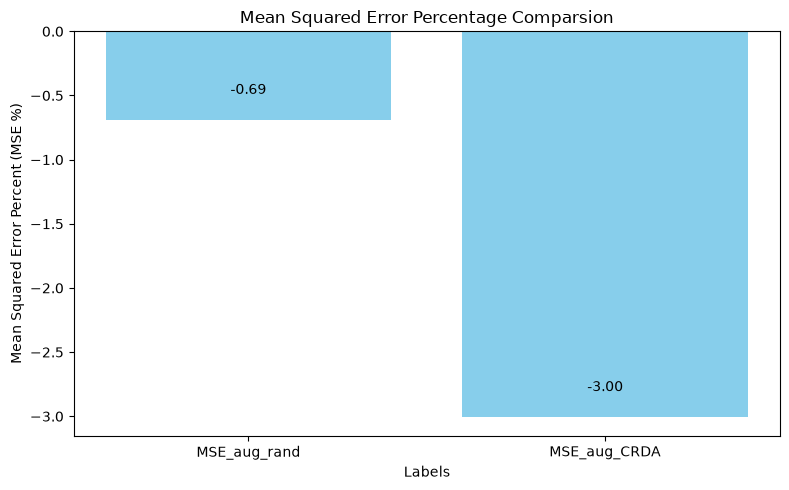

In [59]:
import matplotlib.pyplot as plt

# Example data
MSE_results_labels = ['MSE_aug_rand', 'MSE_aug_CRDA']
MSE_results_values = [MSE_aug_rand_new_percentage, MSE_aug_new_percentage]

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(MSE_results_labels, MSE_results_values, color='skyblue')

plt.title('Mean Squared Error Percentage Comparsion')
plt.xlabel('Labels')
plt.ylabel('Mean Squared Error Percent (MSE %)')

# Add value labels on bars
for i, values in enumerate(MSE_results_values):
    plt.text(i, values + 0.2, f'{values:.2f}', ha='center')

plt.tight_layout()
plt.show()